# P1 — Robustness ranking re-analysis
Session 2 — 25.11.2026 — data download, loading, sanity check for ImageNet16-120

In [ ]:
# A6 — Cell 20: download and place the CIFAR-100 and ImageNet16-120 accuracy files (run once)
from google.colab import drive
drive.mount('/content/drive')
!test -d robustness-data || cp -r /content/drive/MyDrive/P1/robustness-data .
import zipfile, os, shutil
SHARE = "bBnaTnTZWtZqMnE"
BASE = "https://nextcloud.mpi-klsb.mpg.de/public.php/webdav"
for z, d in [("cifar100-accuracies.zip", "cifar100"), ("imagenet-accuracies.zip", "ImageNet16-120")]:
    !curl -s -f -u "{SHARE}:" -o /content/{z} {BASE}/{z}
    os.makedirs(f"robustness-data/{d}", exist_ok=True)
    with zipfile.ZipFile(f"/content/{z}") as zf:
        names = [n for n in zf.namelist() if n.endswith("_accuracy.json")]
        for n in names:
            with zf.open(n) as src, open(f"robustness-data/{d}/{os.path.basename(n)}", "wb") as dst:
                shutil.copyfileobj(src, dst)
    missing = [k for k in ["clean", "fgsm@Linf", "pgd@Linf", "aa_apgd-ce@Linf", "aa_square@Linf"] if not os.path.isfile(f"robustness-data/{d}/{k}_accuracy.json")]
    print(d, "|", len(names), "accuracy files | missing:", missing)
!cp -r robustness-data/cifar100 robustness-data/ImageNet16-120 /content/drive/MyDrive/P1/robustness-data/

Mounted at /content/drive
cifar100 | 20 accuracy files | missing: []
ImageNet16-120 | 5 accuracy files | missing: []


In [ ]:
# Cell 0-setup
from google.colab import drive
drive.mount('/content/drive')
!test -d robustness-data || cp -r /content/drive/MyDrive/P1/robustness-data .
!test -d robustness-dataset || git clone -q https://github.com/steffen-jung/robustness-dataset
import sys
sys.path.append("robustness-dataset")
from robustness_dataset import RobustnessDataset
import pandas as pd

DATASET = "ImageNet16-120"          # A6: "cifar100", then "ImageNet16-120"
data = RobustnessDataset(path="robustness-data")
KEYS = ["clean", "fgsm@Linf", "pgd@Linf", "aa_apgd-ce@Linf", "aa_square@Linf"]
r = data.query(data=DATASET, key=KEYS, measure="accuracy")[DATASET]

def acc(attack, eps):
    i = data.meta["epsilons"][attack].index(eps)
    return {a: v[i] for a, v in r[attack]["accuracy"].items()}

df = pd.DataFrame({
    "clean":    pd.Series(r["clean"]["accuracy"]),
    "fgsm_0.5": pd.Series(acc("fgsm@Linf", 0.5)),
    "fgsm_1":   pd.Series(acc("fgsm@Linf", 1.0)),
    "pgd_1":    pd.Series(acc("pgd@Linf", 1.0)),
    "apgd_1":   pd.Series(acc("aa_apgd-ce@Linf", 1.0)),
    "square_1": pd.Series(acc("aa_square@Linf", 1.0)),
    "apgd_4":   pd.Series(acc("aa_apgd-ce@Linf", 4.0)),
    "square_4": pd.Series(acc("aa_square@Linf", 4.0)),
}).loc[data.non_isomorph_ids]
print(df.shape)

Mounted at /content/drive
(6466, 8)


In [ ]:
# A4 — Cell 10: settings and helper functions
import numpy as np
from scipy.stats import kendalltau, spearmanr

N_CLASSES = 120                                   # CIFAR-10 (A6: 100, then 120)
CHEAP   = ["clean", "fgsm_0.5", "fgsm_1", "pgd_1"]
TARGETS = ["apgd_1", "square_1", "apgd_4", "square_4"]
FRACS   = [0.01, 0.05, 0.10]
OUT     = "/content/drive/MyDrive/P1/"           # results are saved here
TAG     = DATASET                                # used in file names

A = df[df["clean"] >= 2 / N_CLASSES]             # analysis set (plan §3)
print("analysis set:", len(A), "| excluded:", len(df) - len(A))

def topk_weights(x, k):
    kth = np.sort(x)[::-1][k - 1]
    above, tied = x > kth, x == kth
    w = above.astype(float)
    w[tied] = (k - above.sum()) / tied.sum()
    return w

def pair_metrics(c, t, clean):
    out = {"tau": kendalltau(c, t).statistic, "rho": spearmanr(c, t).statistic}
    for f in FRACS:
        k = max(1, round(f * len(c)))
        wc, wt = topk_weights(c, k), topk_weights(t, k)
        out[f"ov{round(f * 100)}"] = wc @ wt / k
        if f == 0.05:
            out["top5_T_byC"] = 100 * (wc @ t) / k
            out["top5_T_byT"] = 100 * (wt @ t) / k
            out["top5_clean_byC"] = 100 * (wc @ clean) / k
    return out

analysis set: 6459 | excluded: 7


In [ ]:
# A6 — Cell 21: data integrity check + best architectures (descriptive, outside the frozen analysis)
import json
print("rows:", len(df), "| unique IDs:", df.index.is_unique, "| missing values:", int(df.isna().sum().sum()))
print("min:", df.min().min(), "| max:", df.max().max())

aid = df.index[0]                                      # one architecture, checked against the raw files
def raw(key):
    with open(f"robustness-data/{DATASET}/{key}_accuracy.json") as f:
        return json.load(f)[DATASET][key]["accuracy"][aid]
for key, cols in [("clean", ["clean"]), ("fgsm@Linf", ["fgsm_0.5", "fgsm_1"]), ("pgd@Linf", ["pgd_1"]),
                  ("aa_apgd-ce@Linf", ["apgd_1", "apgd_4"]), ("aa_square@Linf", ["square_1", "square_4"])]:
    print(aid, key, "| eps:", data.meta["epsilons"].get(key), "| raw:", raw(key), "| df:", df.loc[aid, cols].tolist())

print(df[df["clean"] < 2 / N_CLASSES])                 # the excluded architectures
best = sorted(set(A[c].idxmax() for c in df.columns))  # best architecture per column (first one if tied)
print(A.loc[best].round(3))

rows: 6466 | unique IDs: True | missing values: 0
min: 0.0 | max: 0.473
0 clean | eps: None | raw: 0.277 | df: [0.277]
0 fgsm@Linf | eps: [0.1, 0.5, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 255.0] | raw: [0.206, 0.064, 0.025, 0.012, 0.01, 0.011, 0.012, 0.013, 0.012, 0.013, 0.008] | df: [0.064, 0.025]
0 pgd@Linf | eps: [0.1, 0.5, 1.0, 2.0, 3.0, 4.0, 8.0] | raw: [0.21, 0.054, 0.01, 0.001, 0.0, 0.0, 0.0] | df: [0.01]
0 aa_apgd-ce@Linf | eps: [0.1, 0.5, 1.0, 2.0, 3.0, 4.0, 8.0] | raw: [0.203, 0.034, 0.003, 0.0, 0.0, 0.0, 0.0] | df: [0.003, 0.0]
0 aa_square@Linf | eps: [0.1, 0.5, 1.0, 2.0, 3.0, 4.0, 8.0] | raw: [0.239, 0.072, 0.022, 0.003, 0.002, 0.0, 0.0] | df: [0.022, 0.0]
      clean  fgsm_0.5  fgsm_1  pgd_1  apgd_1  square_1  apgd_4  square_4
10    0.008     0.008   0.008  0.008   0.008     0.008   0.008     0.008
12    0.008     0.008   0.008  0.008   0.008     0.008   0.008     0.008
74    0.008     0.008   0.008  0.008   0.008     0.008   0.008     0.008
172   0.008     0.008   0.008 

In [ ]:
# A4 — Cell 11: point estimates for the 16 pairs
clean = A["clean"].to_numpy()
rows = []
for t in TARGETS:
    T = A[t].to_numpy()
    for c in CHEAP:
        C = A[c].to_numpy()
        m = pair_metrics(C, T, clean)
        m["regret_pp"] = 100 * (T.max() - T[C == C.max()].mean())
        for f in FRACS:
            k = max(1, round(f * len(C)))
            m[f"tiedC_{round(f * 100)}"] = int((C == np.sort(C)[::-1][k - 1]).sum())
            m[f"tiedT_{round(f * 100)}"] = int((T == np.sort(T)[::-1][k - 1]).sum())
        rows.append({"target": t, "cheap": c, **m})
point = pd.DataFrame(rows).set_index(["target", "cheap"])
assert (point["top5_T_byT"] >= point["top5_T_byC"] - 1e-9).all()
point.to_csv(f"{OUT}a4_point_{TAG}.csv")
print(point.round(3).to_string())

                     tau    rho    ov1    ov5  top5_T_byC  top5_T_byT  top5_clean_byC   ov10  regret_pp  tiedC_1  tiedT_1  tiedC_5  tiedT_5  tiedC_10  tiedT_10
target   cheap                                                                                                                                                 
apgd_1   clean    -0.572 -0.701  0.000  0.000       0.036       5.108          45.440  0.000        6.6       10       25       42        7        46        33
         fgsm_0.5  0.245  0.326  0.053  0.432       3.264       5.108          24.853  0.657        4.8       16       25       50        7        47        33
         fgsm_1    0.097  0.128  0.428  0.795       4.393       5.108          21.789  0.623        2.3       17       25       74        7        81        33
         pgd_1     0.742  0.818  0.613  0.980       5.101       5.108          17.362  0.957        0.0       18       25       11        7        26        33
square_1 clean    -0.334 -0.467  0.000  

In [ ]:
# A4 — Cell 12: paired bootstrap (B = 1000, seed 0)
rng = np.random.default_rng(0)
n, B = len(A), 1000
X = {col: A[col].to_numpy() for col in CHEAP + TARGETS}
boot = []
for b in range(B):
    i = rng.integers(0, n, n)                    # the same rows for every pair = paired
    for t in TARGETS:
        for c in CHEAP:
            boot.append({"b": b, "target": t, "cheap": c, **pair_metrics(X[c][i], X[t][i], X["clean"][i])})
    if b % 100 == 0:
        print(b, end=" ")
boot = pd.DataFrame(boot)
boot.to_csv(f"{OUT}a4_bootstrap_{TAG}.csv", index=False)
print("\n", boot.shape)

0 100 200 300 400 500 600 700 800 900 
 (16000, 11)


In [ ]:
# A4 — Cell 13: point estimate [95% percentile interval]
METRICS = ["tau", "rho", "ov1", "ov5", "ov10", "top5_T_byC", "top5_T_byT", "top5_clean_byC"]
g = boot.groupby(["target", "cheap"])[METRICS]
lo, hi = g.quantile(0.025), g.quantile(0.975)
summary = pd.DataFrame(index=point.index)
for m in METRICS:
    summary[m] = [f"{point.loc[ix, m]:.2f} [{lo.loc[ix, m]:.2f}, {hi.loc[ix, m]:.2f}]" for ix in point.index]
summary["regret_pp"] = point["regret_pp"].round(1)
summary.to_csv(f"{OUT}a4_summary_{TAG}.csv")
print(summary.to_string())

                                    tau                   rho                ov1                ov5               ov10         top5_T_byC         top5_T_byT        top5_clean_byC  regret_pp
target   cheap                                                                                                                                                                               
apgd_1   clean     -0.57 [-0.58, -0.56]  -0.70 [-0.71, -0.68]  0.00 [0.00, 0.00]  0.00 [0.00, 0.00]  0.00 [0.00, 0.00]  0.04 [0.03, 0.04]  5.11 [4.92, 5.28]  45.44 [45.34, 45.54]        6.6
         fgsm_0.5     0.24 [0.23, 0.26]     0.33 [0.30, 0.35]  0.05 [0.01, 0.11]  0.43 [0.37, 0.50]  0.66 [0.62, 0.68]  3.26 [3.08, 3.45]  5.11 [4.92, 5.28]  24.85 [24.30, 25.37]        4.8
         fgsm_1       0.10 [0.08, 0.12]     0.13 [0.10, 0.15]  0.43 [0.32, 0.53]  0.80 [0.76, 0.83]  0.62 [0.59, 0.66]  4.39 [4.12, 4.65]  5.11 [4.92, 5.28]  21.79 [20.63, 23.11]        2.3
         pgd_1        0.74 [0.73, 0.75]     0.82 [

In [ ]:
# A5 — Cell 14: floor diagnostics (plan §6)
boot = pd.read_csv(f"{OUT}a4_bootstrap_{TAG}.csv")
rng = np.random.default_rng(0)
IDX = [rng.integers(0, len(A), len(A)) for _ in range(1000)]   # the same resamples as cell 12
fs = pd.Series({t: (A[t] < 0.01).mean() for t in TARGETS})      # floor share per target
rows = []
for t in TARGETS:
    T = A[t].to_numpy()
    for c in CHEAP:
        C = A[c].to_numpy()
        row = {"target": t, "cheap": c, "floor_share": fs[t], "zero_share": (T == 0).mean(), "n_above_1pct": int((T >= 0.01).sum())}
        if row["n_above_1pct"] >= 100:
            keep = T >= 0.01
            bs = [kendalltau(C[i][T[i] >= 0.01], T[i][T[i] >= 0.01]).statistic for i in IDX]
            row.update(cond_tau=kendalltau(C[keep], T[keep]).statistic, cond_lo=np.percentile(bs, 2.5), cond_hi=np.percentile(bs, 97.5))
        rows.append(row)
fl = pd.DataFrame(rows).set_index(["target", "cheap"])
print(fl.round(3).to_string())

                   floor_share  zero_share  n_above_1pct  cond_tau  cond_lo  cond_hi
target   cheap                                                                      
apgd_1   clean           0.869       0.337           849    -0.605   -0.629   -0.579
         fgsm_0.5        0.869       0.337           849     0.080    0.033    0.123
         fgsm_1          0.869       0.337           849     0.604    0.578    0.629
         pgd_1           0.869       0.337           849     0.874    0.864    0.884
square_1 clean           0.001       0.000          6459    -0.337   -0.354   -0.320
         fgsm_0.5        0.001       0.000          6459     0.416    0.401    0.432
         fgsm_1          0.001       0.000          6459     0.282    0.265    0.299
         pgd_1           0.001       0.000          6459     0.651    0.639    0.663
apgd_4   clean           1.000       0.965             0       NaN      NaN      NaN
         fgsm_0.5        1.000       0.965             0       Na

In [ ]:
# A5 — Cell 15: baselines (plan §8)
rng = np.random.default_rng(0)
clean = A["clean"].to_numpy()
rand = pd.DataFrame([{"target": t, **pair_metrics(rng.permutation(len(A)).astype(float), A[t].to_numpy(), clean)}
                     for _ in range(1000) for t in TARGETS]).groupby("target").mean()
print("Random ranking, mean of 1000 permutations:")
print(rand[["tau", "ov1", "ov5", "ov10", "top5_T_byC"]].round(3).to_string())
M = ["ov5", "tau", "top5_T_byC"]
base = boot[boot.cheap == "clean"].set_index(["b", "target"])[M]
for c in ["fgsm_0.5", "fgsm_1"]:
    d = boot[boot.cheap == c].set_index(["b", "target"])[M] - base           # same b = same resample
    est = point.xs(c, level="cheap")[M] - point.xs("clean", level="cheap")[M]
    lo, hi = d.groupby("target").quantile(0.025), d.groupby("target").quantile(0.975)
    print(f"\n{c} minus clean: difference [95% interval]")
    print((est.round(3).astype(str) + " [" + lo.round(3).astype(str) + ", " + hi.round(3).astype(str) + "]").to_string())

Random ranking, mean of 1000 permutations:
          tau    ov1   ov5  ov10  top5_T_byC
target                                      
apgd_1   -0.0  0.011  0.05   0.1       0.506
apgd_4    0.0  0.010  0.05   0.1       0.010
square_1  0.0  0.011  0.05   0.1       2.506
square_4 -0.0  0.010  0.05   0.1       0.181

fgsm_0.5 minus clean: difference [95% interval]
                           ov5                   tau            top5_T_byC
target                                                                    
apgd_1    0.432 [0.374, 0.495]  0.816 [0.794, 0.839]  3.228 [3.048, 3.418]
apgd_4    0.197 [0.153, 0.241]  0.403 [0.375, 0.431]   0.025 [0.02, 0.032]
square_1  0.405 [0.359, 0.451]  0.752 [0.732, 0.774]   3.742 [3.61, 3.874]
square_4  0.238 [0.197, 0.282]  0.331 [0.302, 0.359]  0.092 [0.075, 0.109]

fgsm_1 minus clean: difference [95% interval]
                           ov5                   tau            top5_T_byC
target                                                            

In [ ]:
# A5 — Cell 16: verdicts (plan §7); F is decided first
q = boot.groupby(["target", "cheap"])[["ov5", "tau"]].quantile(0.025)
V = point[["tau", "ov5", "top5_T_byC", "top5_T_byT", "top5_clean_byC", "tiedC_5", "tiedT_5"]].join(fl.reindex(columns=["floor_share", "cond_tau", "cond_lo"]))
V["tau_lo"], V["ov5_lo"] = q["tau"], q["ov5"]
V["selection"] = np.select([V.ov5_lo >= 0.5, V.ov5_lo >= 0.25], ["PASS", "WARN"], "FAIL")
V["outcome"] = np.select([V.floor_share > 0.5, V.selection == "FAIL", V.tau_lo >= 0.5], ["F", "C", "A"], "B")
V["floor_effect"] = np.select([V.floor_share <= 0.5, V.cond_lo.isna(), V.cond_lo >= 0.5], ["", "not assessable", "supported"], "not supported")
V.loc[V.outcome == "F", "selection"] = "—"
V.to_csv(f"{OUT}a5_verdicts_{TAG}.csv")
print(V.round(3).to_string())

                     tau    ov5  top5_T_byC  top5_T_byT  top5_clean_byC  tiedC_5  tiedT_5  floor_share  cond_tau  cond_lo  tau_lo  ov5_lo selection outcome    floor_effect
target   cheap                                                                                                                                                             
apgd_1   clean    -0.572  0.000       0.036       5.108          45.440       42        7        0.869    -0.605   -0.629  -0.584   0.000         —       F   not supported
         fgsm_0.5  0.245  0.432       3.264       5.108          24.853       50        7        0.869     0.080    0.033   0.226   0.374         —       F   not supported
         fgsm_1    0.097  0.795       4.393       5.108          21.789       74        7        0.869     0.604    0.578   0.076   0.761         —       F       supported
         pgd_1     0.742  0.980       5.101       5.108          17.362       11        7        0.869     0.874    0.864   0.731   0.963   

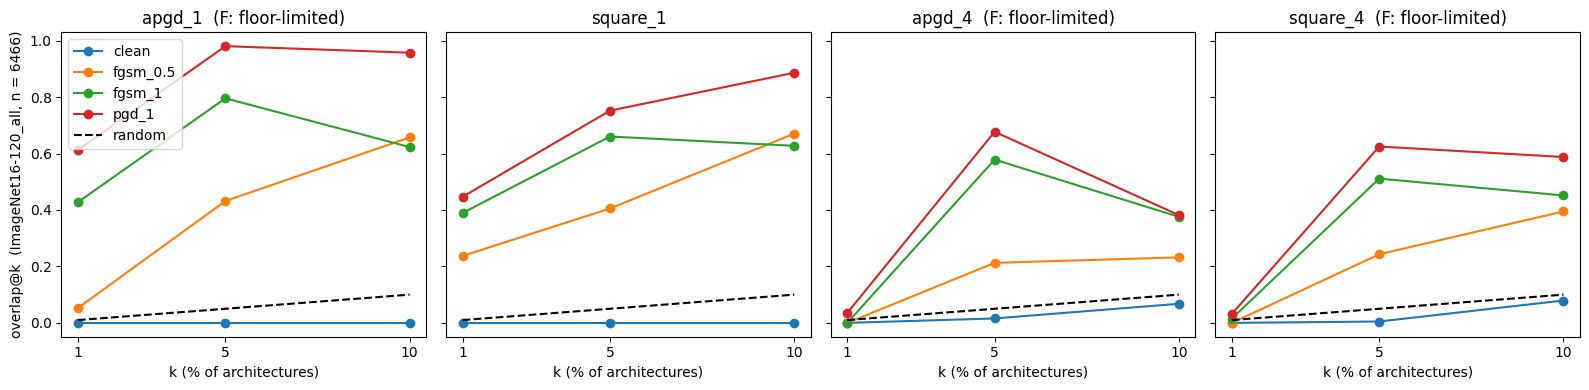

In [ ]:
# A5 — Cell 17: figure overlap@k against k (plan §11)
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, t in zip(axes, TARGETS):
    for c in CHEAP:
        ax.plot([1, 5, 10], point.loc[(t, c), ["ov1", "ov5", "ov10"]].to_numpy(), marker="o", label=c)
    ax.plot([1, 5, 10], [0.01, 0.05, 0.10], "k--", label="random")
    ax.set_title(t + ("  (F: floor-limited)" if fs[t] > 0.5 else ""))
    ax.set_xticks([1, 5, 10])
    ax.set_xlabel("k (% of architectures)")
axes[0].set_ylabel(f"overlap@k  ({TAG}, n = {len(A)})")
axes[0].legend()
plt.tight_layout()
plt.savefig(f"{OUT}a5_overlap_at_k_{TAG}.png", dpi=150)
plt.show()

In [ ]:
# A5 — Cell 18: sensitivity analysis on all architectures (plan §3)
A, TAG = df, DATASET + "_all"
print("architectures:", len(A))

architectures: 6466


In [ ]:
# A6 — Cell 22: verdicts on the analysis set and on all architectures, side by side
cols = ["ov5_lo", "tau_lo", "outcome"]
v = pd.read_csv(f"{OUT}a5_verdicts_{DATASET}.csv", index_col=[0, 1])[cols]
v_all = pd.read_csv(f"{OUT}a5_verdicts_{DATASET}_all.csv", index_col=[0, 1])[cols]
print(v.join(v_all, rsuffix="_all").round(3).to_string())

                   ov5_lo  tau_lo outcome  ov5_lo_all  tau_lo_all outcome_all
target   cheap                                                               
apgd_1   clean      0.000  -0.585       F       0.000      -0.584           F
         fgsm_0.5   0.375   0.227       F       0.374       0.226           F
         fgsm_1     0.761   0.077       F       0.761       0.076           F
         pgd_1      0.961   0.731       F       0.963       0.731           F
square_1 clean      0.000  -0.354       C       0.000      -0.351           C
         fgsm_0.5   0.364   0.401       B       0.359       0.402           B
         fgsm_1     0.618   0.265       B       0.617       0.267           B
         pgd_1      0.713   0.638       A       0.714       0.637           A
apgd_4   clean      0.013  -0.270       F       0.011      -0.274           F
         fgsm_0.5   0.174   0.138       F       0.171       0.125           F
         fgsm_1     0.513   0.232       F       0.515       0.21